In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

In [12]:

X = np.array([
    [1, 50],
    [2, 55],
    [2, 60],
    [3, 65],       # Fail
    [5, 75],
    [6, 80],
    [7, 85],
    [8, 90]        # Pass
])

In [13]:
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

In [14]:

model = SVC(kernel='linear', C=1000)

model.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [15]:

w1 = model.coef_[0][0]
w2 = model.coef_[0][1]
b = model.intercept_[0]

print("w1 =", w1)
print("w2 =", w2)
print("b  =", b)

w1 = 0.038461538461538464
w2 = 0.1923076923076923
b  = -13.615384615384613


In [16]:

print("\nDecision Boundary:")
print(f"{w1:.4f} x1 + {w2:.4f} x2 + {b:.4f} = 0")


Decision Boundary:
0.0385 x1 + 0.1923 x2 + -13.6154 = 0


In [17]:

print("\nSupport Vectors:")
print(model.support_vectors_)


Support Vectors:
[[ 3. 65.]
 [ 5. 75.]]


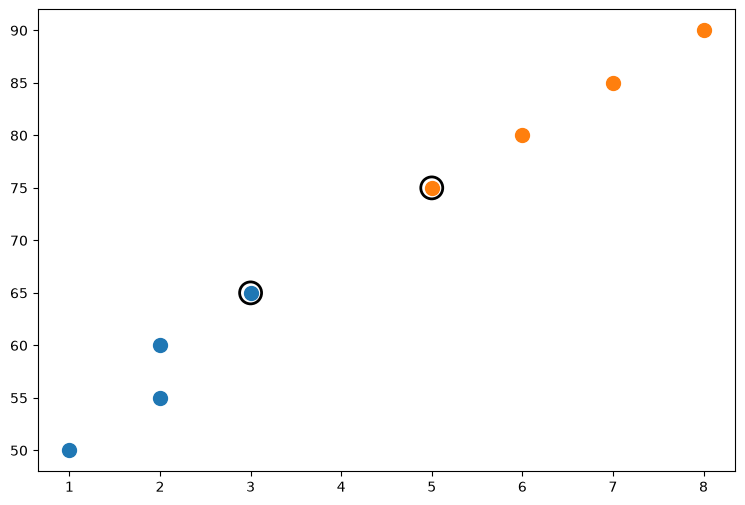

In [18]:

plt.figure(figsize=(9, 6))


plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    s=100,
    label='Fail (Class 0)'
)


plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    s=100,
    label='Pass (Class 1)'
)


plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=250,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    label='Support Vectors'
)


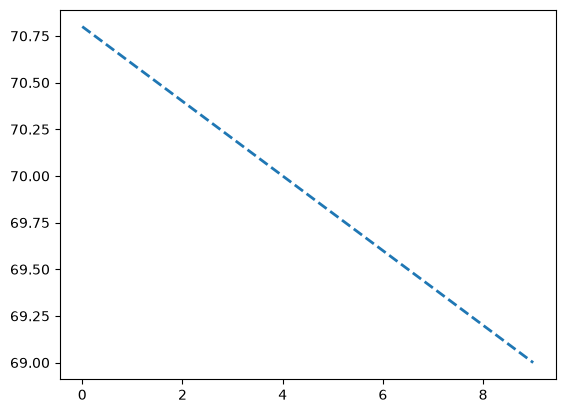

In [19]:

x1_values = np.linspace(0, 9, 100)

# w1*x1 + w2*x2 + b = 0
# Therefore:
# x2 = -(w1*x1 + b) / w2

x2_values = -(w1 * x1_values + b) / w2

plt.plot(
    x1_values,
    x2_values,
    linestyle='--',
    linewidth=2,
    label='Decision Boundary'
)

C:\Users\abhis\AppData\Local\Temp\ipykernel_10504\3388287552.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


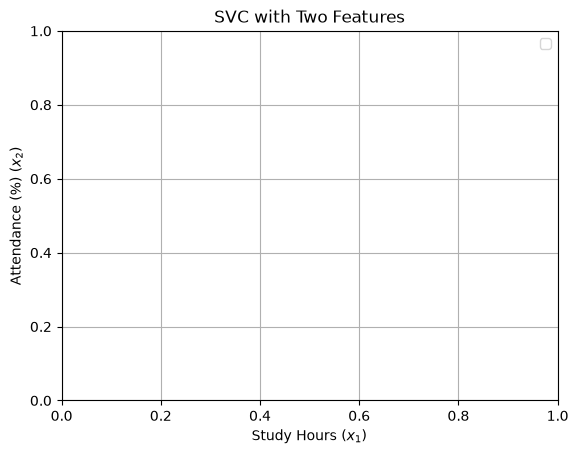

In [ ]:

plt.xlabel('Study Hours ($x_1$)')
plt.ylabel('Attendance (%) ($x_2$)')

plt.title('SVC with Two Features')

plt.legend()
plt.grid(True)

plt.show()